In [1]:
from rdkit import Chem
from rdkit.Chem.rdFMCS import FindMCS
from rdkit import RDLogger
import numpy as np
import sys
import time
from anytree import Node, RenderTree
sys.path.append('molecule-web-app/backend/rules')  # replace with your local path
sys.path.append('molecule-web-app/backend')
# Now you can import your module as usual
from rules import execute_step, run_next_step
import helper
from ml_helper import make_fingerprint
from next_step import follow_on

import xgboost
import pickle

In [2]:
# Load the model
clf = xgboost.XGBClassifier()
clf.load_model('models/v31/xg_model.json')

In [27]:
sm_smiles = '[NH4+].O=CCCC=O'
end_smiles = 'O.[OH3+].N1C=CC=C1'
sm = Chem.MolFromSmiles(sm_smiles)
end = Chem.MolFromSmiles(end_smiles)
sm_node = Node("SM", mol=sm)


In [ ]:
# Parameters
force_depth = False
depth_limit = 10
boost = 0
resort_limit = 1000000
force_correct_last_step = True
aromatic = False
follow_on_enabled = False 
# Initialise variables
step_no = 0
product_nodes = []
times_per_layer = []
nodes = [sm_node]
signal_break = False
unique_id = 0
current_max_depth = 0
best_node = None
highest_sim = 0


inchi2 = Chem.MolToInchi(end, options='FixedH')
RDLogger.DisableLog('rdApp.*') 
while step_no < depth_limit:
    product_count = 0
    start_t = time.time()
    print(f'step no {step_no}')
    nodes_to_next = []
    for int in nodes:
        if product_count > resort_limit:
            print(f"Resorting nodes at step {step_no} at depth {current_max_depth}")
            break
        similarity = FindMCS([int.mol, end]).numAtoms
        if hasattr(int, 'priority'):
            p_boost = int.priority + int.depth
        else:
            p_boost = 0
        if hasattr(int, 'product'):
            continue
        try:
            product_mols, mechs, mol_inp  = run_next_step("Placeholder", aromatic, True, int.mol)
        except Exception as e:
            continue
        for i, product in enumerate(product_mols):
            fp = np.array(make_fingerprint(mol_inp, mechs[i]))
            pred = clf.predict(fp.reshape(1,-1))[0]
            try:
                inchi1 = Chem.MolToInchi(product, options='FixedH')
                
            except Exception as e:
                print(f'Error processing product {i}: {e}')
                continue
            if inchi1 == inchi2:
                print('Found the target molecule!')
                print(f'The final step (mol {unique_id}) was predicted: {pred}')
                if force_correct_last_step and pred != 1:
                        continue
                new_node = Node(f"Mol {unique_id}", parent=int, mol=product, mech=mechs[i])
                new_node.priority = -100
                new_node.product = True
                unique_id += 1
                product_nodes.append(new_node)
                if not (force_depth and step_no < depth_limit):
                    signal_break = True
                break
            elif pred == 1:
                new_node = Node(f"Mol {unique_id}", parent=int, mol=product, mech=mechs[i])
                if follow_on_enabled:
                    try:
                        f_mols, f_smiles = follow_on(product, mechs[i], clf)
                    except:
                        print("issue with follow on mol")
                    for fm in f_mols:
                        unique_id += 1
                        f_node = Node(f"Mol {unique_id}", parent=int, mol=fm, mech="follow_on")
                        try:
                            inchi1 = Chem.MolToInchi(fm, options='FixedH')
                        except Exception as e:
                            print(f'Error processing product {i}: {e}')
                            continue
                        if inchi1 == inchi2:
                            print('Found the target molecule!')
                            print(f'The final step (mol {unique_id}) was predicted: {pred}')
                            if force_correct_last_step and pred != 1:
                                    continue
                            f_node.priority = -100
                            f_node.product = True
                            if force_depth and step_no < depth_limit:
                                product_nodes.append(f_node)
                            else:  
                                product_nodes.append(new_node)
                                signal_break = True
                            break
                    if signal_break:
                        break
                #num_MCS = FindMCS([product, end]).numAtoms
                #new_node.similarity = num_MCS
                #if num_MCS > similarity: # if there is a greater substructure match than the current node
                   # new_node.priority = - new_node.depth + num_MCS * boost + p_boost
                    #if num_MCS > highest_sim:
                        #highest_sim = num_MCS
                        #best_node = new_node
                #else:
                   # new_node.priority = - new_node.depth + p_boost # TODO: consider some decay here
                if new_node.depth > current_max_depth:
                    current_max_depth = new_node.depth
                
                unique_id += 1
        if signal_break:
            break
    if signal_break:
        print("we breaking")
        break
    nodes = sm_node.leaves
    #nodes = sorted(nodes, key=lambda x: x.priority)
    step_no += 1
    end_t = time.time()
    times_per_layer.append(end_t - start_t)

print("search is over")

       


step no 0
step no 1
step no 2
step no 3
step no 4
step no 5
step no 6
step no 7
Found the target molecule!
The final step (mol 5068) was predicted: 0
Found the target molecule!
The final step (mol 5183) was predicted: 0
Found the target molecule!
The final step (mol 5186) was predicted: 0
Found the target molecule!
The final step (mol 8743) was predicted: 0
Found the target molecule!
The final step (mol 12278) was predicted: 0
step no 8
Found the target molecule!
The final step (mol 21851) was predicted: 0
Found the target molecule!
The final step (mol 22764) was predicted: 0
Found the target molecule!
The final step (mol 22805) was predicted: 0
Found the target molecule!
The final step (mol 22810) was predicted: 0
Found the target molecule!
The final step (mol 23027) was predicted: 0
Found the target molecule!
The final step (mol 23234) was predicted: 0
Found the target molecule!
The final step (mol 23237) was predicted: 0
Found the target molecule!
The final step (mol 23329) was pred

In [5]:
for i, dur in enumerate(times_per_layer):
    print(f'Layer {i+1} took {dur:.2f} seconds')

Layer 1 took 0.04 seconds
Layer 2 took 0.04 seconds
Layer 3 took 0.21 seconds
Layer 4 took 2.44 seconds
Layer 5 took 27.44 seconds
Layer 6 took 343.79 seconds


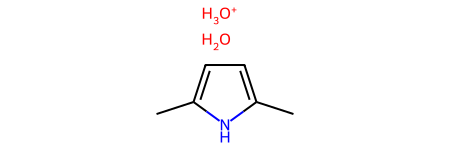

In [6]:
end

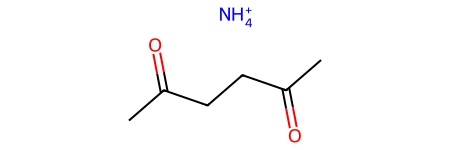

In [7]:
sm

In [8]:
sm_node.size

387673

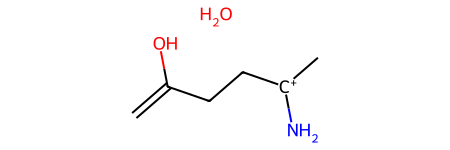

In [9]:
sm_node.leaves[10678].mol


In [10]:
len(product_nodes)

1

In [11]:
def visualise_tree(node):
    mols = [node.mol]
    while node.is_root is False:
        node = node.parent
        mols.append(node.mol)
    mols.reverse()
    return Chem.Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(400, 400), legends=[f"Mol {i}" for i in range(len(mols))])

In [ ]:
def pickle_tree(node, name="reaction_path", idx=0):
    mols = [node.mol]
    while node.is_root is False:
        node = node.parent
        mols.append(node.mol)
    mols.reverse()
    pickle.dump(mols, open(f"{name}_{idx}.pkl", "wb"))
    print(f"Pickled reaction path {idx} to {name}_{idx}.pkl")
    return None

In [12]:
def visualise_tree_png(node):
    mols = [node.mol]
    while node.is_root is False:
        node = node.parent
        mols.append(node.mol)
    mols.reverse()
    return Chem.Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(700, 700), legends=[f"Mol {i}" for i in range(len(mols))], returnPNG=True)

In [13]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices  =True

In [14]:
#for i, p in enumerate(product_nodes):
#    pickle_tree(p, idx=i)

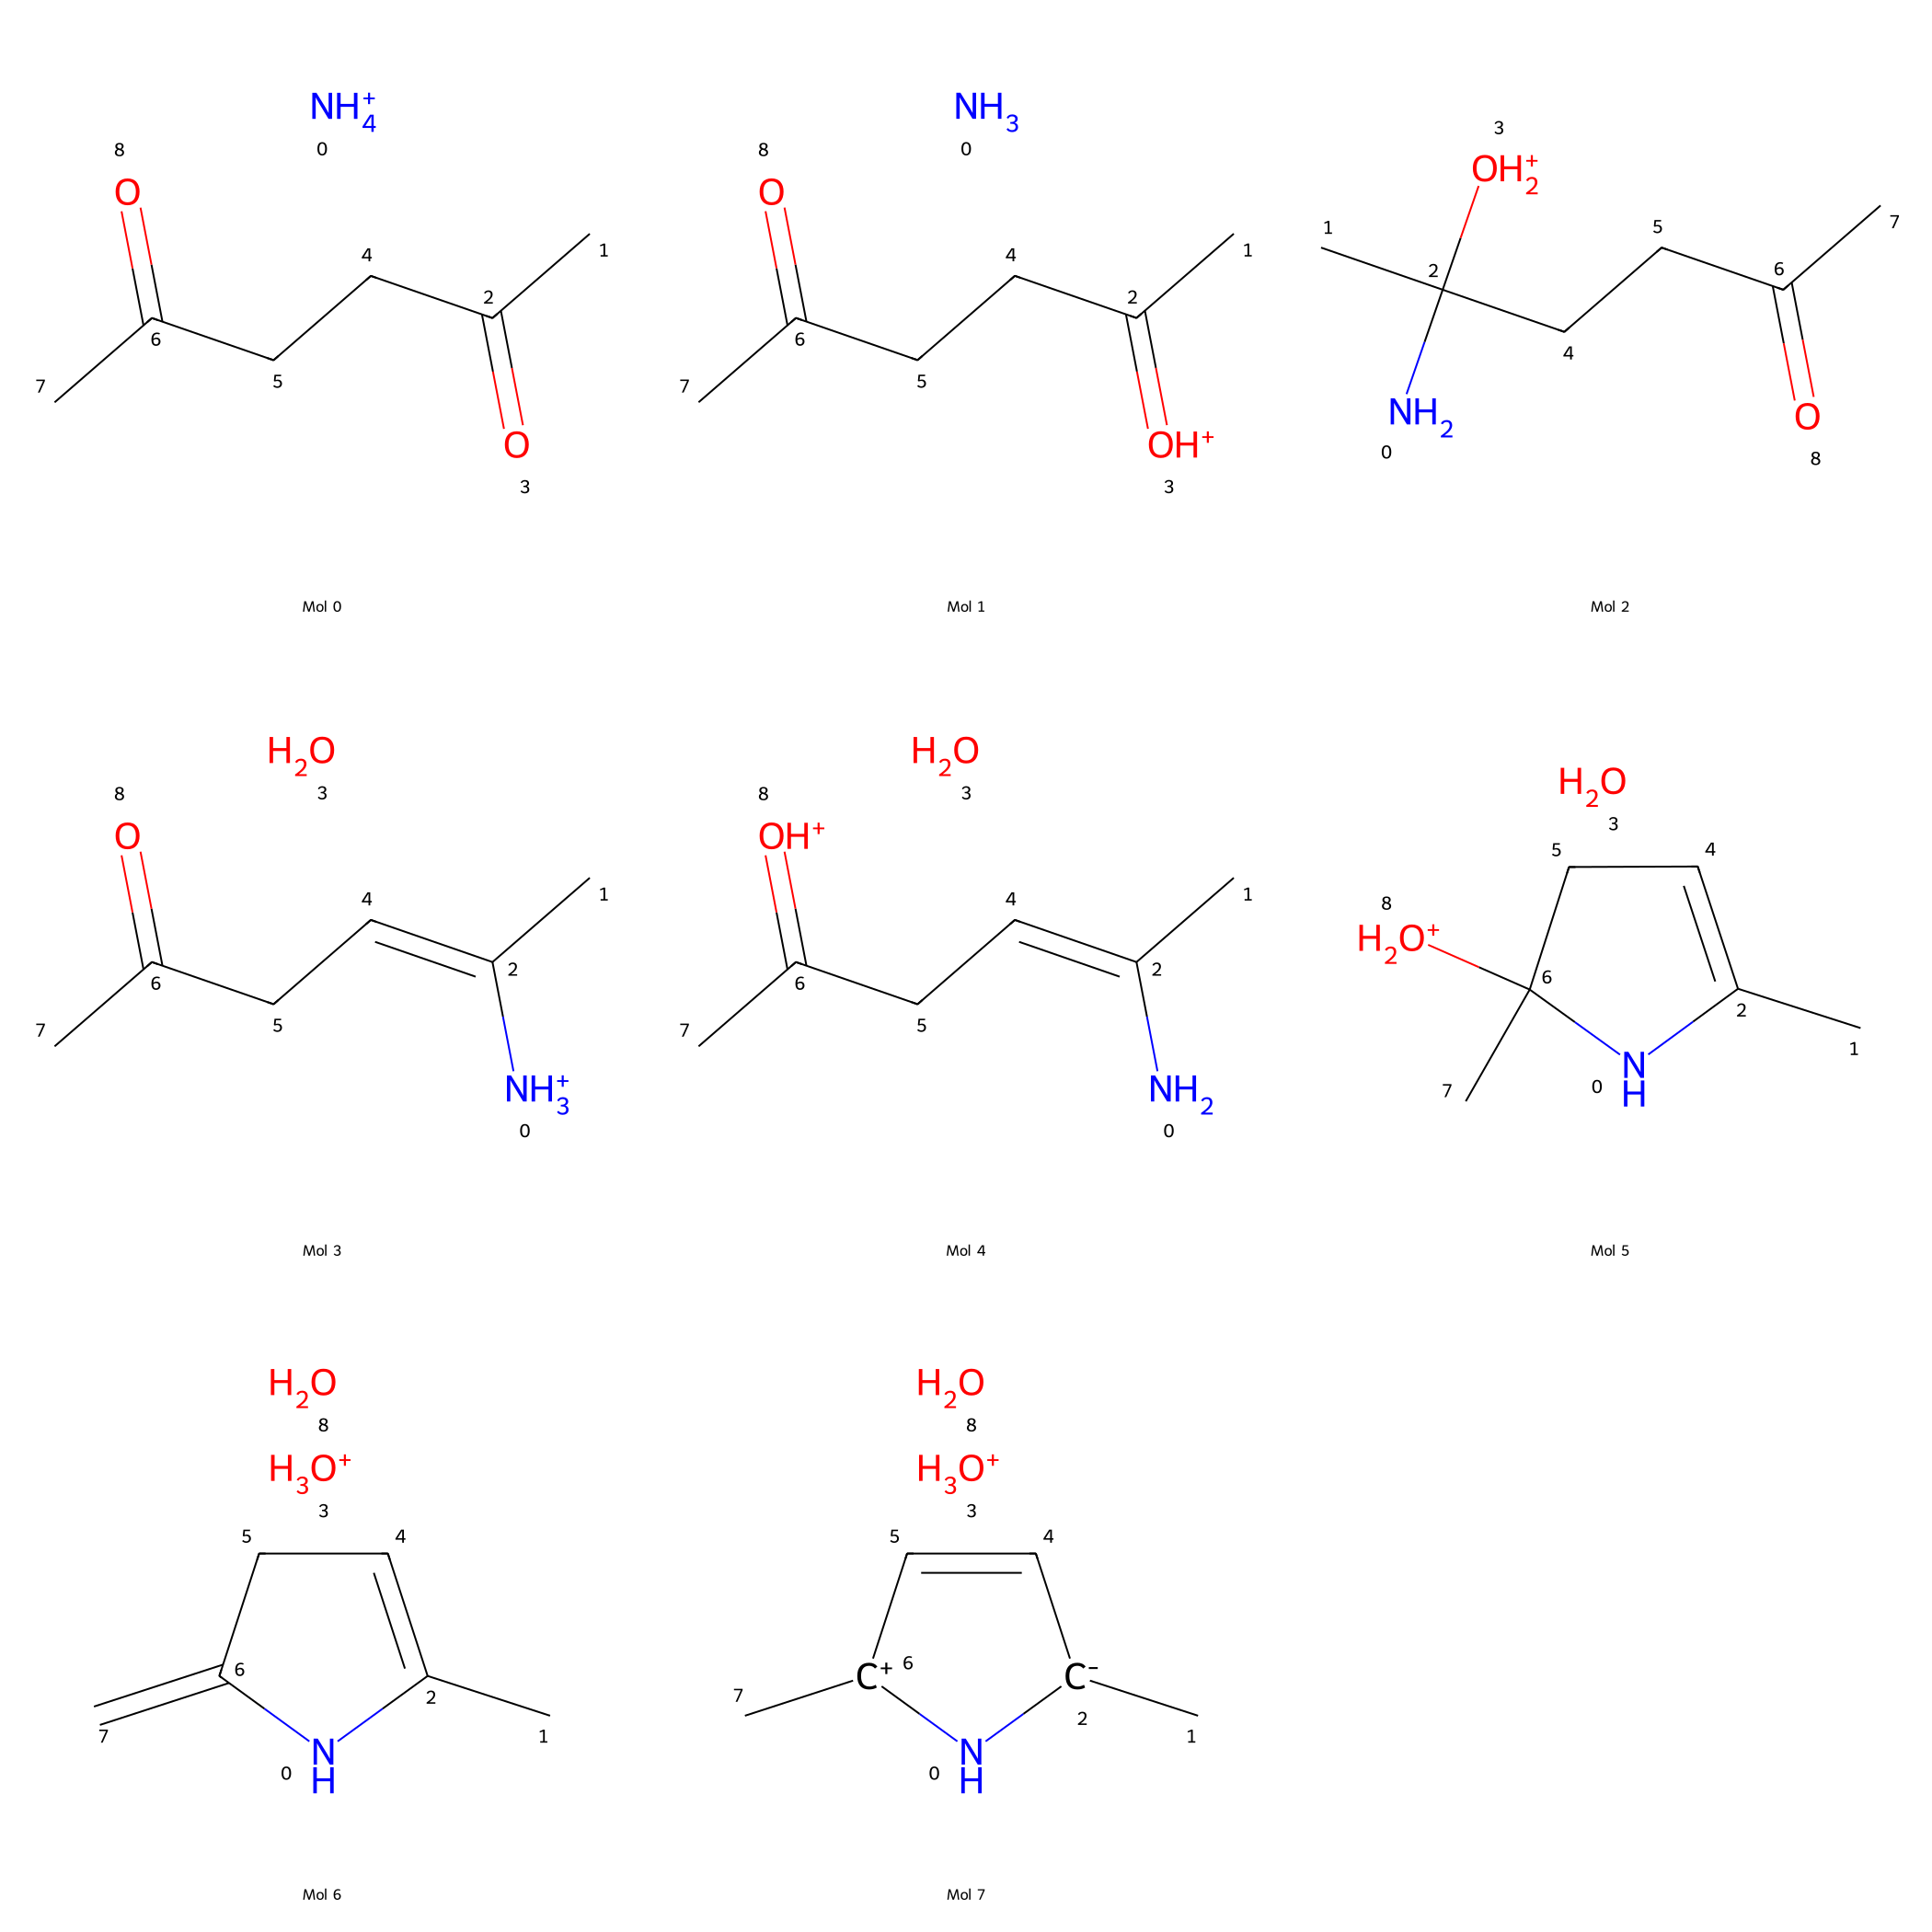

In [15]:
visualise_tree_png(product_nodes[0])

In [17]:
for pre, fill, node in RenderTree(sm_node):
    print(f"{pre}{node.name} - {Chem.MolToSmiles(node.mol)}")
    #if hasattr(node, 'mech'):
    #    print(f"{pre}Mechanism: {node.mech}")
    #else:
    #    print(f"{pre}Mechanism: None")

SM - CC(=O)CCC(=O)O.[BH4-].[OH3+]
├── Mol 0 - CC(=[OH+])CCC(=O)O.O.[BH4-]
│   ├── Mol 6 - C=C(O)CCC(=O)O.[BH4-].[OH3+]
│   ├── Mol 7 - CC(=O)CCC(=O)O.[BH4-].[OH3+]
│   ├── Mol 8 - CC(O)=CCC(=O)O.[BH4-].[OH3+]
│   ├── Mol 9 - CC(=[OH+])CCC(=O)[O-].[BH4-].[OH3+]
│   ├── Mol 10 - CC(=[OH+])CCC(=O)[OH2+].[BH4-].[OH-]
│   ├── Mol 11 - CC(=O)CCC(=O)[OH2+].O.[BH4-]
│   ├── Mol 12 - CC(=[OH+])CCC(O)=[OH+].[BH4-].[OH-]
│   ├── Mol 13 - CC(=O)CCC(O)=[OH+].O.[BH4-]
│   ├── Mol 14 - CC(O)([OH2+])CCC(=O)O.[BH4-]
│   ├── Mol 15 - CC(=[OH+])CCC([O-])(O)[OH2+].[BH4-]
│   ├── Mol 16 - CC1(O)CCC(=O)[OH+]1.O.[BH4-]
│   ├── Mol 17 - B.CC(O)CCC(=O)O.O
│   └── Mol 18 - B.CC(=[OH+])CCC([O-])O.O
├── Mol 1 - CC(=O)CCC(=O)[OH2+].O.[BH4-]
│   ├── Mol 19 - C=C([O-])CCC(=O)[OH2+].[BH4-].[OH3+]
│   ├── Mol 20 - CC([O-])=CCC(=O)[OH2+].[BH4-].[OH3+]
│   ├── Mol 21 - CC(=O)CCC(=O)O.[BH4-].[OH3+]
│   ├── Mol 22 - CC(=[OH+])CCC(=O)[OH2+].[BH4-].[OH-]
│   ├── Mol 23 - CC(=[OH+])CCC(=O)O.O.[BH4-]
│   ├── Mol 24 - CC(=O)CC

In [18]:
product_nodes[0].parent.parent.mech

'follow_on'

In [18]:
Chem.Draw.MolsToGridImage([m.mol for m in best_node.children])
#best_node.depth

AttributeError: 'NoneType' object has no attribute 'children'

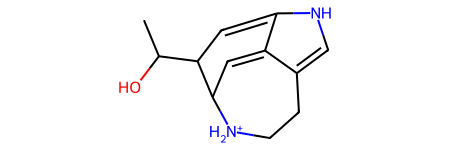

In [8]:
best_node.mol

In [13]:
execute_step('CC1=CCC([C+](C)C)CC1.O', True, False, None, False)

[9, 10, 4, 5, None]
[0, 10, 5, None, None]
[9, 10, 6, 5, None]
[1, 10, 1, None, 2]
[1, 10, 2, None, 1]
[9, 1, 4, 5, None]
[9, 2, 4, 5, None]
[1, 1, 5, 2, None]
[1, 2, 5, 1, None]
[9, 1, 6, 5, None]
[9, 2, 6, 5, None]
[5, 1, 10, 2, None]
[5, 2, 10, 1, None]


([<rdkit.Chem.rdchem.Mol at 0x7f86c92051c0>,
 [[9, 10, 4, 5, None],
  [0, 10, 5, None, None],
  [9, 10, 6, 5, None],
  [1, 10, 1, None, 2],
  [1, 10, 2, None, 1],
  [9, 1, 4, 5, None],
  [9, 2, 4, 5, None],
  [1, 1, 5, 2, None],
  [1, 2, 5, 1, None],
  [9, 1, 6, 5, None],
  [9, 2, 6, 5, None],
  [5, 1, 10, 2, None],
  [5, 2, 10, 1, None]],
 <rdkit.Chem.rdchem.Mol at 0x7f86c9204ba0>)

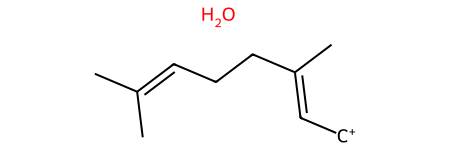

In [14]:
sm

In [15]:
mols, mechs, mol_inp = execute_step('O.CC(C)=CCCC(C)=C[CH2+]', True, False, None, False)

[9, 0, 9, 10, None]
[0, 0, 10, None, None]
[1, 0, 2, None, 4]
[1, 0, 4, None, 2]
[1, 0, 7, None, 9]
[1, 0, 9, None, 7]
[5, 2, 0, 4, None]
[5, 4, 0, 2, None]
[9, 2, 9, 10, None]
[9, 4, 9, 10, None]
[1, 2, 10, 4, None]
[1, 4, 10, 2, None]
[5, 7, 0, 9, None]
[5, 9, 0, 7, None]
[9, 7, 9, 10, None]
[1, 7, 10, 9, None]
[1, 9, 10, 7, None]
[3, 2, 7, 4, 9]
[3, 4, 7, 2, 9]
[3, 2, 9, 4, 7]
[3, 4, 9, 2, 7]
[3, 7, 2, 9, 4]
[3, 9, 2, 7, 4]
[3, 7, 4, 9, 2]
[3, 9, 4, 7, 2]


In [24]:
mols, mechs, mol_inp = execute_step('P', True, False, b, False)

[9, 0, 1, 2, None]
[0, 0, 2, None, None]
[9, 0, 4, 2, None]
[1, 0, 7, None, 9]
[1, 0, 9, None, 7]
[5, 7, 0, 9, None]
[5, 9, 0, 7, None]
[9, 7, 1, 2, None]
[9, 9, 1, 2, None]
[1, 7, 2, 9, None]
[1, 9, 2, 7, None]
[9, 7, 4, 2, None]
[9, 9, 4, 2, None]


In [16]:
for i, mol in enumerate(mols):
    fp = np.array(make_fingerprint(mol_inp, mechs[i]))
    if clf.predict(fp.reshape(1,-1))[0]==1:
        print(f'Predicted product {i} is a valid reaction product')

Predicted product 1 is a valid reaction product
Predicted product 11 is a valid reaction product


In [17]:
b = Chem.Mol(mols[11])

In [18]:
clf.predict(fp.reshape(1,-1))

array([0])

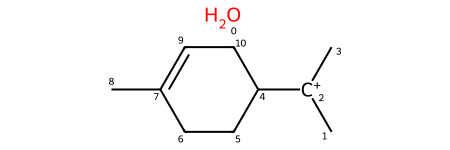

In [23]:
b

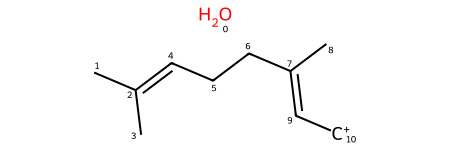

In [22]:
mol_inp

In [21]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

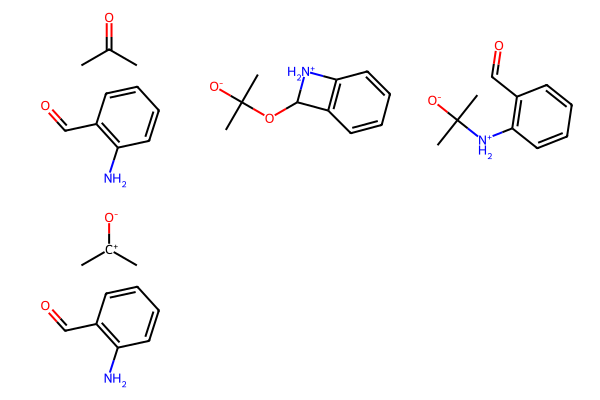

In [29]:
some_mols = [m.mol for m in new_node.parent.children]
Chem.Draw.MolsToGridImage(some_mols)

MCS: [#6]-[#6](:,-[#7]:,-[#6]1:[#6](:[#6]:[#6]:[#6]:[#6]:1):,-[#6]):,-[#6], num atoms: 11, num bonds: 11


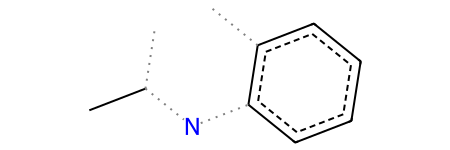

In [40]:
from rdkit.Chem.rdFMCS import FindMCS
result = FindMCS([some_mols[2], end])
print(f'MCS: {result.smartsString}, num atoms: {result.numAtoms}, num bonds: {result.numBonds}')
Chem.MolFromSmarts(result.smartsString)